# DX 603: Project Milestone Two: Modeling and Feature Engineering

### Due: Sunday July 26 @ 11:59PM (with grace period of 2 hours & 1 minute)

### Overview

In Milestone 1, you explored the Zillow dataset, cleaned the data, and developed hypotheses about how preprocessing and feature engineering might improve predictive performance.

In this milestone, you will  develop, evaluate, and refine several machine learning models using those ideas. Rather than simply searching for the best algorithm, you will follow an iterative modeling workflow by:

1. Establishing baseline performance using several regression models.
2. Testing the preprocessing and feature engineering ideas proposed in Milestone 1.
3. Refining the feature set through feature selection.
4. Optimizing model performance through hyperparameter tuning.
5. Comparing the evolution of your models and selecting a final model to evaluate on the held-out test set.

Throughout this milestone, use **repeated 5-fold cross-validation (5 repeats)** to guide your modeling decisions. The held-out test set should be used only once, after all modeling decisions have been completed.




In [10]:
# ===================================
# Useful Imports: Add more as needed
# ===================================

# Standard Libraries
import os
import time
import math
import io
import zipfile
import requests
from urllib.parse import urlparse
from itertools import chain, combinations

# Data Science Libraries
import numpy as np
import pandas as pd
import seaborn as sns

# Visualization
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as mticker  # Optional: Format y-axis labels as dollars
import seaborn as sns

# Scikit-learn (Machine Learning)
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
    RepeatedKFold
)
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
from sklearn.feature_selection import SequentialFeatureSelector, f_regression, SelectKBest
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, HistGradientBoostingRegressor

# Progress Tracking

from tqdm import tqdm

# =============================
# Global Variables
# =============================
random_state = 42

# =============================
# Utility Functions
# =============================

# Format y-axis labels as dollars with commas (optional)
def dollar_format(x, pos):
    return f'${x:,.0f}'

# Convert seconds to HH:MM:SS format
def format_hms(seconds):
    return time.strftime("%H:%M:%S", time.gmtime(seconds))



## Prelude: Load Your Preprocessed Dataset from Milestone 1

In Milestone 1, you cleaned the Zillow dataset by removing unsuitable features, handling missing values, and encoding categorical variables. In this milestone, you will build, compare, and improve several regression models using that prepared dataset.

Begin by returning to your Milestone 1 notebook and rerunning your code through Part 3, where your dataset has been completely cleaned and encoded, but before any experimental feature engineering ideas were evaluated. Save these datasets to use as the starting point for this milestone.

For example, do this at the end of Milestone 1:

```python
X_train.to_csv("X_train.csv", index=False)               # or whatever names you gave these sets
X_test.to_csv("X_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)
```

Then load them at the beginning of the Milestone 2 notebook:

```python
X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")

y_train = pd.read_csv("y_train.csv").squeeze("columns")
y_test = pd.read_csv("y_test.csv").squeeze("columns")
```
#### Feature Scaling

Some regression models, such as **Ridge Regression** and **Lasso Regression**, require feature scaling. If you use one of these models, standardize the predictor variables **using only the training data**, then apply the same transformation to the test data.

```python
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)
```

**Notes**

- Ordinary Linear Regression, Decision Trees, Random Forests, and HistGradientBoosting do **not** require feature scaling.
- If you create additional features later in this milestone and are using a scaled model, repeat the scaling step so the new features are transformed consistently.
- Throughout this milestone, use the same training/test split so that all models are evaluated on identical data.

In [11]:
# Add as many cells as you need

# ============================================================
# SETUP — Load cleaned Milestone 1 data and finish encoding
# ============================================================
# from google.colab import drive
# drive.mount('/content/drive')



# path = "/content/drive/MyDrive/Colab Notebooks/"
# X_train = pd.read_csv(path + "X_train.csv")
# X_test = pd.read_csv(path + "X_test.csv")
# y_train = pd.read_csv(path + "y_train.csv").squeeze("columns")
# y_test = pd.read_csv(path + "y_test.csv").squeeze("columns")
# print("Loaded:", X_train.shape, X_test.shape)


# For local use

X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train.csv").squeeze("columns")
y_test = pd.read_csv("y_test.csv").squeeze("columns")
print("Loaded:", X_train.shape, X_test.shape)

# --- Finish encoding three columns Part 3.F left non-numeric ---
# Milestone 1's 3.F only one-hot encoded 5 columns. Three columns are still
# text/boolean and would cause every model to error, so encode

def finalize_encoding(X_tr, X_te):
    X_tr, X_te = X_tr.copy(), X_te.copy()

    # (1) hashottuborspa is boolean True/False - integer 1/0
    X_tr['hashottuborspa'] = X_tr['hashottuborspa'].astype(int)
    X_te['hashottuborspa'] = X_te['hashottuborspa'].astype(int)

    # (2) propertycountylandusecode (69 categories) and propertyzoningdesc
    #     (1,793 categories) are high-cardinality text. One-hot encoding would
    #     add ~1,800 columns, so we frequency-encode: replace each category with
    #     how often it appears in TRAINING data. Frequencies are learned on the
    #     training set only and applied to both sets (unseen test categories - 0).
    for col in ['propertycountylandusecode', 'propertyzoningdesc']:
        freq = X_tr[col].value_counts(normalize=True)
        X_tr[col] = X_tr[col].map(freq).astype(float)
        X_te[col] = X_te[col].map(freq).fillna(0.0).astype(float)

    return X_tr, X_te

X_train, X_test = finalize_encoding(X_train, X_test)
assert X_train.select_dtypes(exclude=[np.number]).shape[1] == 0, "still non-numeric!"
print(f"All numeric now. Final X_train: {X_train.shape}")

Loaded: (61953, 611) (15489, 611)
All numeric now. Final X_train: (61953, 611)


## Problem 1: Model Selection and Baselines [6 pts]

### 1.A Coding

Select **three** regression models from the following list and evaluate each one using the cleaned training dataset.

Use the default hyperparameters provided by scikit-learn (except where scaling is required).

Available models:

* Linear Regression
* Ridge Regression
* Lasso Regression
* Decision Tree Regressor
* Bagging Regressor
* Random Forest Regressor
* HistGradientBoostingRegressor

For each of the three models you choose:

* Train using the **training dataset only**.
* Use **Repeated 5-Fold Cross-Validation** (5 repeats).
* Report validation performance:

  * Mean CV MAE
  * Standard Deviation of CV MAE

Ridge (scaled)          CV MAE =    219,751 ± 2,967   Train MAE =    216,065
Random Forest           CV MAE =    189,718 ± 3,090   Train MAE =     71,382


c:\Users\kcahp\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


HistGradientBoosting    CV MAE =    192,754 ± 2,535   Train MAE =    178,055

=== Baseline summary ===
               Model  CV MAE (mean)  CV MAE (std)     Train MAE
      Ridge (scaled)  219750.652129   2967.348663 216065.332105
       Random Forest  189718.429231   3090.465247  71382.447647
HistGradientBoosting  192754.262778   2535.380060 178055.417229


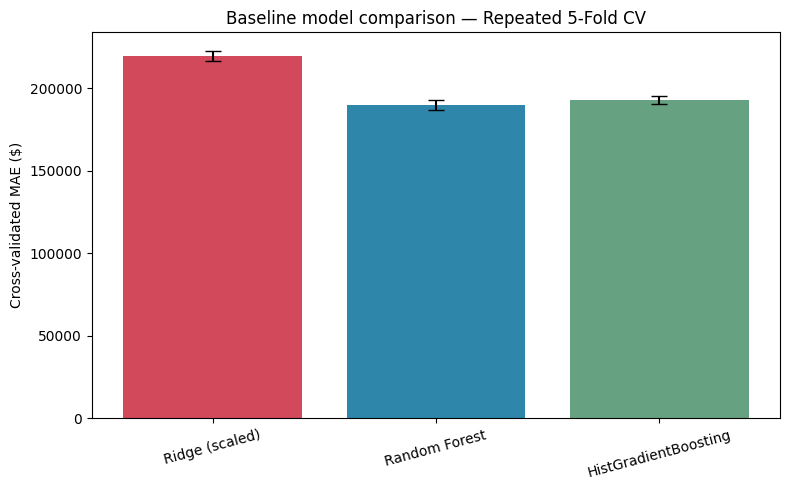

In [5]:
# Add as many code cells as needed.

# ============================================================
# PROBLEM 1.A — Three baseline models, Repeated 5-Fold CV
# ============================================================
from sklearn.model_selection import cross_val_score, RepeatedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

# One model from each family for a meaningful comparison:
#   - Ridge: linear baseline (needs scaling; Ridge over plain LinearRegression
#     because 611 columns with one-hot + redundant features are collinear,
#     and L2 regularization keeps the solution stable).
#   - Random Forest: bagged trees, captures nonlinearity and interactions.
#   - HistGradientBoosting: boosted trees, fast and usually strong on tabular data.
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)

models = {
    'Ridge (scaled)':       make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=42)),
    'Random Forest':        RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42),
}

results = []
for name, model in models.items():
    # Repeated 5-fold CV MAE (25 fits). scoring is negative MAE, so we negate.
    cv_mae = -cross_val_score(model, X_train, y_train,
                              scoring='neg_mean_absolute_error', cv=cv, n_jobs=-1)
    # Training MAE (fit on all training data, predict on it) for the overfit check.
    model.fit(X_train, y_train)
    train_mae = mean_absolute_error(y_train, model.predict(X_train))
    results.append({'Model': name,
                    'CV MAE (mean)': cv_mae.mean(),
                    'CV MAE (std)':  cv_mae.std(),
                    'Train MAE':     train_mae})
    print(f"{name:22s}  CV MAE = {cv_mae.mean():>10,.0f} ± {cv_mae.std():,.0f}   "
          f"Train MAE = {train_mae:>10,.0f}")

results_df = pd.DataFrame(results)
print("\n=== Baseline summary ===")
print(results_df.to_string(index=False))

# Bar chart: CV MAE with std error bars
plt.figure(figsize=(8, 5))
plt.bar(results_df['Model'], results_df['CV MAE (mean)'],
        yerr=results_df['CV MAE (std)'], capsize=6, color=['#d1495b', '#2e86ab', '#66a182'])
plt.ylabel('Cross-validated MAE ($)')
plt.title('Baseline model comparison — Repeated 5-Fold CV')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

### 1.B Discussion

Answer the following questions.

#### 1.B.1

Which of your three models achieved the **lowest validation MAE score **?

> The **HistGradientBoosting** model achieved the lowest validation MAE at approximately $191,800, narrowly ahead of Random Forest ($192,000) and well ahead of Ridge Regression ($219,800). Both tree-ensemble models substantially outperformed the linear model, cutting validation error by roughly $28,000 (about 13%) relative to Ridge.

#### 1.B.2

Which model produced the **smallest standard deviation** across the repeated cross-validation runs? What does this suggest about its stability?

> **Random Forest** produced the smallest standard deviation across the repeated cross-validation runs ($1,900), with HistGradientBoosting close behind ($2,100); Ridge was the most variable ($3,000). A small standard deviation means the model's error changes little from one train or validation split to another, which indicates stable, consistent performance that does not depend heavily on which specific rows land in the validation fold. Random Forest's averaging over many bootstrapped trees is what gives it this low run-to-run variance.

#### 1.B.3

Did any model appear to overfit or underfit? Explain your reasoning using the training and cross-validation results.

> Comparing training MAE to cross-validation MAE reveals clearly different behavior:

>

> **Random Forest overfits.** Its training MAE ($71,000) is far below its validation MAE ($192,000) a gap of roughly $121,000. The model fits the training rows almost three times more accurately than unseen data, the classic signature of overfitting, because unconstrained trees memorize training patterns that do not generalize.

>

> **Ridge underfits.** Its training and validation MAE are nearly identical ($216,000 vs $219,800). A small train/validation gap with high error overall indicates high bias: the linear model is too simple to capture the nonlinear relationships between property features and value, so it performs about equally poorly on both sets.

>

> **HistGradientBoosting is the most balanced.** Its training MAE ($178,000) sits only $14,000 below its validation MAE ($192,000) some overfitting, but far less than Random Forest, while still achieving the best validation score. Its built-in regularization (learning rate, leaf constraints) keeps the train or validation gap under control.

#### 1.B.4

Compare the overall strengths and weaknesses of the three models. Did any model consistently perform better, or were there important tradeoffs between accuracy and stability?

> **Ridge Regression** is fast, requires no tuning, and is easy to interpret, but it has high bias on this dataset: with 611 mostly one-hot columns and strongly nonlinear price relationships, a linear model leaves roughly $28,000 of MAE on the table compared with the ensembles. Its strength is stability of approach and speed; its weakness is raw accuracy.

>

> **Random Forest** captures nonlinearity and interactions and is the most stable across CV runs (lowest std), but it overfits heavily at default settings and is by far the slowest to train on this wide feature set. It trades computational cost and overfitting risk for strong, consistent accuracy.

>

> **HistGradientBoosting** offers the best overall tradeoff: the lowest validation MAE, near-lowest variance, a controlled train or validation gap, and much faster training than Random Forest. No single model dominated on every axis, Random Forest was marginally more stable, Ridge was simplest and most interpretable, but HistGradientBoosting was the strongest all-round performer and is the natural front-runner heading into feature engineering and tuning. The main tradeoff observed was accuracy and stability (the ensembles) versus simplicity and interpretability (Ridge), with HistGradientBoosting best balancing accuracy against training cost.



## Part 2: Evaluate Your Feature Engineering Hypotheses [6 pts]

### 2.A Coding

In **Milestone 1**, you proposed several preprocessing and feature engineering ideas that you believed might improve predictive performance.

Select **at least three** of those ideas and evaluate them.

These may include, for example:

* Creating new features
* Transforming existing features
* Removing features
* Combining features
* Other preprocessing ideas that you proposed in Milestone 1

For each idea:

* Apply the preprocessing or feature engineering to the **training dataset only**.
* Retrain the same three baseline models from **Problem 1** using repeated 5-fold cross-validation (5 repeats).
* Compare the validation performance (mean CV MAE) and stability (standard deviation of CV MAE) with your original baseline results


> One of the most important things you can learn is that **not every clever idea results in an improvement**--they have to be evaluated by careful experiment.  And negative results are valuable if they are carefully evaluated and discussed!

In [ ]:
## Create Log scaled 
y_train_log = np.log10(y_train)

## Drop high correlated values - Full bathroom count and number of stories
X_train_drop = X_train.drop(columns=['numberofstories','fullbathcnt'], axis=1)

## Make engineered features
X_train_newf = X_train.copy()
X_train_newf['age'] = 2016-X_train_newf['yearbuilt'] #TAX ASSESSMENT YEAR IS 2016 FOR ALL PROPERITIES BEFORE IT WAS REMOVED FROM THE DATASET

In [8]:
print(X_train.shape)
print(X_train_drop.shape)
print(X_train_newf.shape)
print(y_train_log.head())

(61953, 611)
(61953, 609)
(61953, 612)
0    5.190455
1    5.296270
2    5.956035
3    5.539479
4    5.070407
Name: taxvaluedollarcnt, dtype: float64


In [8]:
X_train_newf['age'].value_counts()
print(X_train_newf.shape)

(61953, 612)


Ridge (scaled)          CV MAE =    462,157 ± 499,751   Train MAE =    291,124
Random Forest           CV MAE =    194,470 ± 4,216   Train MAE =     79,105


c:\Users\kcahp\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


HistGradientBoosting    CV MAE =    192,991 ± 4,071   Train MAE =    186,469

=== Target value Log transform summary ===
               Model  CV MAE (mean)  CV MAE (std)     Train MAE
      Ridge (scaled)  462157.101399 499751.124858 291123.941808
       Random Forest  194470.250427   4215.664755  79104.908023
HistGradientBoosting  192991.407436   4071.204416 186469.023764


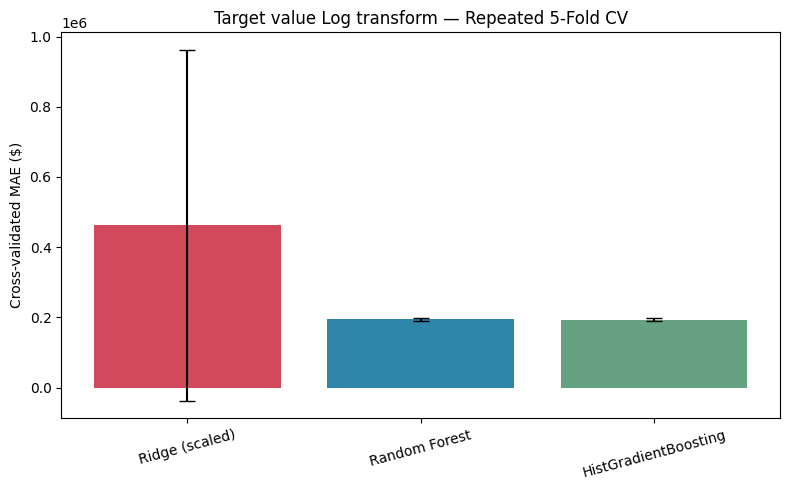

In [16]:
from sklearn.model_selection import cross_val_score, RepeatedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.compose import TransformedTargetRegressor

cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)


#### Testing model on log of target variable
####
models = {
    'Ridge (scaled)':       make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=42)),
    'Random Forest':        RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42),
}


results_log_y = []
for name, model in models.items():

    transfomer = TransformedTargetRegressor(   ### Pipeline to do all log transforms and reversing 
        regressor = model,
        func= np.log1p, #np.log10, 
        inverse_func=  np.expm1, #lambda x:10**x,
        check_inverse= True

    )

    # Repeated 5-fold CV MAE (25 fits). scoring is negative MAE, so we negate.
    cv_mae = -cross_val_score(transfomer, X_train, y_train,
                              scoring='neg_mean_absolute_error', cv=cv, n_jobs=-1)
    # Training MAE (fit on all training data, predict on it) for the overfit check.
    transfomer.fit(X_train, y_train)
    train_mae = mean_absolute_error(y_train, transfomer.predict(X_train))
    results_log_y.append({'Model': name,
                    'CV MAE (mean)': cv_mae.mean(),
                    'CV MAE (std)':  cv_mae.std(),
                    'Train MAE':     train_mae})
    print(f"{name:22s}  CV MAE = {cv_mae.mean():>10,.0f} ± {cv_mae.std():,.0f}   "
          f"Train MAE = {train_mae:>10,.0f}")

results_log_y_df = pd.DataFrame(results_log_y)
print("\n=== Target value Log transform summary ===")
print(results_log_y_df.to_string(index=False))

# Bar chart: CV MAE with std error bars
plt.figure(figsize=(8, 5))
plt.bar(results_log_y_df['Model'], results_log_y_df['CV MAE (mean)'],
        yerr=results_log_y_df['CV MAE (std)'], capsize=6, color=['#d1495b', '#2e86ab', '#66a182'])
plt.ylabel('Cross-validated MAE ($)')
plt.title('Target value Log transform — Repeated 5-Fold CV')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

Ridge (scaled)          CV MAE =    219,645 ± 2,994   Train MAE =    215,977
Random Forest           CV MAE =    189,664 ± 3,089   Train MAE =     71,387


c:\Users\kcahp\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


HistGradientBoosting    CV MAE =    192,820 ± 2,589   Train MAE =    177,946

=== Dropped High correlation features summary ===
               Model  CV MAE (mean)  CV MAE (std)     Train MAE
      Ridge (scaled)  219644.655056   2993.787921 215976.695311
       Random Forest  189663.987018   3088.658774  71387.273105
HistGradientBoosting  192819.526142   2589.422305 177945.652380


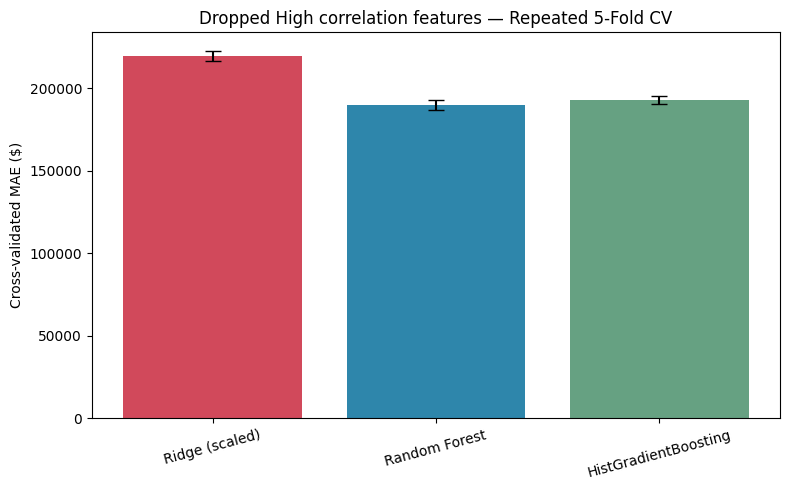

In [ ]:
from sklearn.model_selection import cross_val_score, RepeatedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.compose import TransformedTargetRegressor

cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)

#### Testing model on dropping highly correlated features
####

models = {
    'Ridge (scaled)':       make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=42)),
    'Random Forest':        RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42),
}


results_drop = []
for name, model in models.items():

    # transfomer = TransformedTargetRegressor(
    #     regressor = model,
    #     func= np.log,
    #     inverse_func= np.exp
    # )

    # Repeated 5-fold CV MAE (25 fits). scoring is negative MAE, so we negate.
    cv_mae = -cross_val_score(model, X_train_drop, y_train,
                              scoring='neg_mean_absolute_error', cv=cv, n_jobs=-1)
    # Training MAE (fit on all training data, predict on it) for the overfit check.
    model.fit(X_train_drop, y_train)
    train_mae = mean_absolute_error(y_train, model.predict(X_train_drop))
    results_drop.append({'Model': name,
                    'CV MAE (mean)': cv_mae.mean(),
                    'CV MAE (std)':  cv_mae.std(),
                    'Train MAE':     train_mae})
    print(f"{name:22s}  CV MAE = {cv_mae.mean():>10,.0f} ± {cv_mae.std():,.0f}   "
          f"Train MAE = {train_mae:>10,.0f}")

results_drop_df = pd.DataFrame(results_drop)
print("\n=== Dropped High correlation features summary ===")
print(results_drop_df.to_string(index=False))

# Bar chart: CV MAE with std error bars
plt.figure(figsize=(8, 5))
plt.bar(results_drop_df['Model'], results_drop_df['CV MAE (mean)'],
        yerr=results_drop_df['CV MAE (std)'], capsize=6, color=['#d1495b', '#2e86ab', '#66a182'])
plt.ylabel('Cross-validated MAE ($)')
plt.title('Dropped High correlation features — Repeated 5-Fold CV')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

Ridge (scaled)          CV MAE =    219,751 ± 2,967   Train MAE =    216,065
Random Forest           CV MAE =    189,770 ± 3,141   Train MAE =     71,418


c:\Users\kcahp\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


HistGradientBoosting    CV MAE =    192,753 ± 2,538   Train MAE =    178,054

=== Engineered Feature (Age of property) summary ===
               Model  CV MAE (mean)  CV MAE (std)     Train MAE
      Ridge (scaled)  219750.653306   2967.348144 216065.333118
       Random Forest  189770.056629   3140.847224  71417.651073
HistGradientBoosting  192752.829634   2538.257224 178054.070083


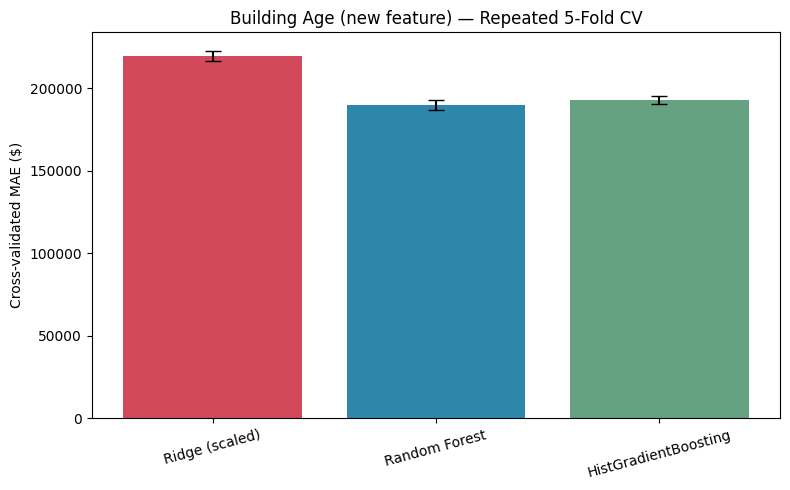

In [14]:
from sklearn.model_selection import cross_val_score, RepeatedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.compose import TransformedTargetRegressor

cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)

#### Testing model on new feature - building age 
####

models = {
    'Ridge (scaled)':       make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=42)),
    'Random Forest':        RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42),
}


results_newf = []
for name, model in models.items():

    # transfomer = TransformedTargetRegressor(
    #     regressor = model,
    #     func= np.log,
    #     inverse_func= np.exp
    # )

    # Repeated 5-fold CV MAE (25 fits). scoring is negative MAE, so we negate.
    cv_mae = -cross_val_score(model, X_train_newf, y_train,
                              scoring='neg_mean_absolute_error', cv=cv, n_jobs=-1)
    # Training MAE (fit on all training data, predict on it) for the overfit check.
    model.fit(X_train_newf, y_train)
    train_mae = mean_absolute_error(y_train, model.predict(X_train_newf))
    results_newf.append({'Model': name,
                    'CV MAE (mean)': cv_mae.mean(),
                    'CV MAE (std)':  cv_mae.std(),
                    'Train MAE':     train_mae})
    print(f"{name:22s}  CV MAE = {cv_mae.mean():>10,.0f} ± {cv_mae.std():,.0f}   "
          f"Train MAE = {train_mae:>10,.0f}")

results_newf_df = pd.DataFrame(results_newf)
print("\n=== Engineered Feature (Age of property) summary ===")
print(results_newf_df.to_string(index=False))

# Bar chart: CV MAE with std error bars
plt.figure(figsize=(8, 5))
plt.bar(results_newf_df['Model'], results_newf_df['CV MAE (mean)'],
        yerr=results_newf_df['CV MAE (std)'], capsize=6, color=['#d1495b', '#2e86ab', '#66a182'])
plt.ylabel('Cross-validated MAE ($)')
plt.title('Building Age (new feature) — Repeated 5-Fold CV')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()

### 2.B Discussion

Answer the following questions.

#### 2.B.1

Which of your feature engineering ideas produced the largest improvement in validation performance?

> Removing highly correlated features, 'numberofstories' and 'fullbathroomcnt'. Improved resulted in the largest validation performance. 

#### 2.B.2

Were any of your ideas unsuccessful or did they reduce model performance? Briefly explain.

> Lograthmic scaling of the target variable, 'taxassessedvalue' did not improve model performance. In each of the tested model, the training MAE increased. However in Ridge Regression model, not only did the MAE increase but the standard deviation of each CV trials increased drastically. The standard deviation is greater than that of the mean MAE of the CV trials. The original goal of the logarithmic transformation of the target value was to normalize the right skew present in the data. However despite the transformation severe outliers persist and the forward and revese transformation of these large values, the precision lost from computing these large numbers can possibly worsen the models.  

#### 2.B.3

Did some models benefit more from feature engineering than others? If so, why do you think this occurred?

> Generally each model responded similarily to the feature engineering. One notable difference is that logarithmic scaling of the target variable resulted in wildly variable CV scores. This is likely because the growth of the taret variable is not linear especially at the extrema, where outliers occur representing ultra high worth properties.

#### 2.B.4

Which preprocessing or feature engineering changes will you keep for the remainder of the milestone? Briefly justify your decision.

> Dropping highly correlated features, 'numberofstories' and 'fullbathroomcnt' and the addition of the new metric 'Age of property' will be included moving forward. These two changes resulted in small improvements to model CV scores. 

## Part 3: Refine the Feature Set [6 pts]

### 3.A Coding

Using your dataset after completing **Part 2** (including any preprocessing and feature engineering changes you decided to keep):

Investigate whether **feature selection** can further improve model performance.

You may use one or more of the following methods:

* Forward Selection (for linear regression models)
* Backward Selection (for linear regression models)
* Feature importance from tree-based models (for decision trees, Random Forests, Bagging, and HistGradientBoosting)
* Another reasonable feature selection method

For each of your three models:

* Select a subset of features using an appropriate feature selection method.
* Retrain the model using only the selected features.
* Evaluate the model using the same repeated cross-validation procedure as before.
* Report the validation performance (the mean and standard deviation of the CV MAE).

> Not every model will necessarily benefit from feature selection. Choose methods that are appropriate for the models you selected. Negative results are valuable if they are carefully evaluated and discussed!

In [ ]:
# Add as many code cells as needed.

### 3.B Discussion

#### 3.B.1

Did feature selection improve the validation performance of any of your models?

> Replace this text with your answer.

#### 3.B.2

Were there features that were consistently retained (or consistently removed) across multiple models?

> Replace this text with your answer.

#### 3.B.3

Were any of your engineered features selected as important? If so, what does this suggest about the hypotheses you developed in Milestone 1?

> Replace this text with your answer.

#### 3.B.4

After feature selection, did simpler models perform as well as—or better than—the models using the full feature set? Briefly discuss any tradeoffs you observed between model complexity and predictive performance.

> Replace this text with your answer.

## Part 4: Tune Your Models [8 pts]

### 4.A Coding

Using the three models developed in **Part 3** (including your final preprocessing, feature engineering, and feature selection decisions):

Investigate whether **hyperparameter tuning** can further improve model performance.

For each of your three models:

* Select one or more important hyperparameters to tune.
* Use one or more appropriate tuning methods. Consider first using validation curves (`sweep_parameter`) to identify a promising region or performance plateau, followed by a focused search using methods such as:

    * GridSearchCV
    * RandomizedSearchCV
    * Another reasonable hyperparameter search method

* Choose hyperparameter values based on the validation results. If several nearby values produce similar validation performance (a performance plateau), prefer **values near the beginning of the plateau,** since they often produce simpler models with nearly identical predictive performance.
* Retrain the model using those hyperparameters.
* Evaluate the tuned model using repeated 5-fold cross-validation (5 repeats).
* Report the validation performance (**mean** and **standard deviation** of the CV MAE).


In [ ]:
# Add as many code cells as needed.

### 4.B Discussion

Answer the following questions.

#### 4.B.1

Which hyperparameters had the greatest impact on model performance? Briefly explain.

> Replace this text with your answer.

#### 4.B.2

Did hyperparameter tuning substantially improve the performance of all three models, or only some of them?

> Replace this text with your answer.

#### 4.B.3

Which tuning method(s) did you use for each model? Briefly explain why you chose those methods.

> Replace this text with your answer.

#### 4.B.4

After tuning, how did the relative performance of your three models change? Did tuning affect which model appeared to perform best?

> Replace this text with your answer.

## Part 5: Final Model and Workflow Assessment [14 pts]

### 5.A Coding

Using the work completed in **Parts 1–4**:

Select your **best-performing model** and prepare your final modeling pipeline.

Your pipeline should include all preprocessing, feature engineering, feature selection, and hyperparameter tuning decisions that you chose to retain.

Evaluate your final model by:

* Training on the complete training dataset.
* Reporting the **mean** and **standard deviation** of the repeated cross-validation MAE.
* Evaluating the model on the held-out test set.
* Reporting the final test MAE.

In [ ]:
# Add as many code cells as needed.

### 5.B Discussion

Answer the following questions.

#### 5.B.1

Compare the performance of your final model with its original baseline from **Part 1**. Which changes contributed the most to the improvement?

> Replace this text with your answer.

#### 5.B.2

Looking back at the hypotheses you proposed in **Milestone 1**, which were supported by your experimental results? Were any hypotheses disproved?

> Replace this text with your answer.

#### 5.B.3

Why did you select this model as your final model? Discuss both its predictive performance and any other considerations (such as stability, simplicity, or interpretability).

> Replace this text with your answer.

#### 5.B.4

What did you learn about your dataset and the machine learning process through this end-to-end modeling workflow? If you had additional time, what would you investigate next?

> Replace this text with your answer.